# TP : Facteurs de risque d'un portefeuille (marché, taille, valeur)

**Durée estimée :** 2 heures · **Niveau :** premier cycle universitaire, bases de Python et de statistique

## Objectifs

À la fin de ce TP, vous saurez :

1. identifier le **type de problème** (régression linéaire multiple) et justifier ce choix ;
2. charger des données publiques depuis une URL et construire un portefeuille à partir de Yahoo Finance ;
3. préparer les données (aligner les dates, convertir en rendements en excès) sans erreur de calendrier ;
4. estimer et comparer un modèle à un facteur (CAPM) et un modèle à trois facteurs (Fama-French) à partir d'une référence simple ;
5. évaluer les modèles avec des tests de significativité, le R² ajusté, l'intervalle de confiance de l'alpha et des diagnostics sur les résidus ;
6. interpréter les résultats et en connaître les limites (alpha dû au hasard, biais de survie).

## 1. De quel type de problème s'agit-il ?

**Question** : la rentabilité d'un portefeuille s'explique-t-elle par le marché, la taille et la valeur ?

Il s'agit d'une **régression linéaire multiple** : la cible $y$ (le rendement en excès du portefeuille) est une **valeur réelle**, et non une classe. Ce serait une classification si l'on cherchait à prédire une catégorie (« hausse » ou « baisse »).

Le but est ici **explicatif** plus que prédictif : on cherche à mesurer la sensibilité du portefeuille à chaque facteur (les **bêtas**) et la part de rendement non expliquée (l'**alpha**), avec des tests statistiques. Le modèle est :

$$R_p - R_f = \alpha + \beta_1 (R_m - R_f) + \beta_2\, SMB + \beta_3\, HML + \varepsilon$$

- **Mkt-RF** : prime de risque du marché ;
- **SMB** (*Small Minus Big*) : rendement des petites capitalisations moins celui des grandes ;
- **HML** (*High Minus Low*) : rendement des titres « valeur » (rapport valeur comptable/prix élevé) moins celui des titres « croissance ».

> **Remarque.** Ce TP suit la démarche du TP sur les manchots (explorer, préparer, comparer à une référence, évaluer, interpréter), mais l'objectif change : on **estime et teste** un modèle linéaire plutôt que de classer.

## 2. Les données

| Source | Contenu |
|---|---|
| **Fama-French** (Université Dartmouth, fichier zip à décompresser) | `Mkt-RF`, `SMB`, `HML`, `RF` : rendements mensuels en % |
| **Yahoo Finance** (`yfinance`) | cours ajustés mensuels des titres du portefeuille, fournis par l'étudiant |

| Variable | Type | Description |
|---|---|---|
| `Rp_exc` | numérique (cible) | rendement mensuel du portefeuille moins le taux sans risque (%) |
| `Mkt-RF` | numérique | prime de risque du marché (%) |
| `SMB` | numérique | facteur taille (%) |
| `HML` | numérique | facteur valeur (%) |
| `RF` | numérique | taux sans risque mensuel (%) |

In [23]:
# Importation des bibliothèques
import io, zipfile, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import statsmodels.api as sm
from statsmodels.regression.rolling import RollingOLS
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.stats.diagnostic import het_breuschpagan
import yfinance as yf

# Reproductibilité et style des graphiques
np.random.seed(42)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110

### 2.1 Chargement des facteurs Fama-French

Le fichier est téléchargé depuis l'URL officielle puis **décompressé en mémoire**, sans téléchargement manuel.
Si le site est inaccessible, déposez `F-F_Research_Data_Factors.csv` dans les fichiers de Colab (icône dossier à gauche) et relancez la cellule.

In [24]:
URL_FF = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/F-F_Research_Data_Factors_CSV.zip"
NOM_CSV = "F-F_Research_Data_Factors.csv"

def lire_ff():
    try:
        r = requests.get(URL_FF, timeout=30, headers={"User-Agent": "Mozilla/5.0"})
        r.raise_for_status()
        with zipfile.ZipFile(io.BytesIO(r.content)) as z:
            nom = [n for n in z.namelist() if n.lower().endswith(".csv")][0]
            return z.read(nom).decode("latin-1")
    except Exception as e:
        print("Téléchargement impossible :", e)
        if os.path.exists(NOM_CSV):
            print("Utilisation du fichier local", NOM_CSV)
            return open(NOM_CSV, encoding="latin-1").read()
        raise

texte = lire_ff()

# On garde les lignes mensuelles (date AAAAMM) ; le fichier contient aussi un tableau annuel plus bas
lignes = [l for l in texte.splitlines() if len(l.split(",")[0].strip()) == 6 and l.split(",")[0].strip().isdigit()]
ff = pd.read_csv(io.StringIO("Date,Mkt-RF,SMB,HML,RF\n" + "\n".join(lignes)))
ff["Date"] = ff["Date"].astype(str).str.strip()
for c in ["Mkt-RF", "SMB", "HML", "RF"]:
    ff[c] = pd.to_numeric(ff[c], errors="coerce")
ff = ff.dropna().reset_index(drop=True)

print("Dimensions :", ff.shape, "| période :", ff["Date"].min(), "->", ff["Date"].max())
ff.head()

Dimensions : (1203, 5) | période : 192607 -> 202609


,Date,Mkt-RF,SMB,HML,RF
0,192607,2.89,-2.42,-2.75,0.22
1,192608,2.64,-1.44,4.13,0.25
2,192609,0.38,-1.36,0.05,0.23
3,192610,-3.27,-0.18,0.78,0.32
4,192611,2.54,-0.17,-0.48,0.31


### 2.2 Construction du portefeuille

Le portefeuille est **à pondérations égales** (rééquilibré chaque mois). Les tickers ci-dessous sont un exemple : **remplacez-les par votre propre sélection** (c'est à l'étudiant de fournir le portefeuille).

In [25]:
tickers_list = ["XOM", "JPM", "JNJ", "PG", "WMT", "GE", "T", "KO", "CVX", "PFE"]
poids = pd.Series(1 / len(tickers_list), index=tickers_list)

prix = yf.download(tickers_list, start="2014-12-01", end="2025-12-31",
                   interval="1mo", auto_adjust=True, progress=False)["Close"][tickers_list]

# Rendements mensuels en %, puis rendement du portefeuille
rend = prix.pct_change().dropna(how="all") * 100
rend["Portefeuille"] = (rend[tickers_list] * poids).sum(axis=1)

# Alignement du format de date avec Fama-French (AAAAMM)
rend.index = pd.to_datetime(rend.index).strftime("%Y%m")
rend = rend.rename_axis("Date").reset_index()
print("Dimensions :", rend.shape)
rend.head()

Dimensions : (132, 12)


Ticker,Date,XOM,JPM,JNJ,PG,WMT,GE,T,KO,CVX,PFE,Portefeuille
0,201501,-5.440793,-12.544227,-4.236412,-6.806998,-1.047941,-5.461013,-0.145312,-2.487001,-8.602247,0.321041,-4.645090
1,201502,2.043524,12.688439,3.083214,0.996589,-1.235600,9.790332,4.981791,5.173716,5.069835,10.792802,5.338464
2,201503,-3.998210,-1.142257,-1.863235,-3.747266,-1.413058,-4.540194,-5.526587,-5.573970,-1.593569,1.369499,-2.802885
3,201504,2.788276,5.117937,-1.391616,-2.185079,-5.106399,9.149559,8.123972,0.024654,5.791582,-2.472006,1.984088
4,201505,-1.677143,3.983603,1.683703,-1.408613,-4.242486,0.701605,-0.288700,0.986178,-6.333177,3.264180,-0.333085


### Mon portefeuille

- **Composition** : 10 grandes entreprises américaines de secteurs différents :
  - énergie : Exxon Mobil (XOM), Chevron (CVX) ;
  - finance : JPMorgan Chase (JPM) ;
  - santé : Johnson & Johnson (JNJ), Pfizer (PFE) ;
  - consommation de base : Procter & Gamble (PG), Walmart (WMT), Coca-Cola (KO) ;
  - industrie : General Electric (GE) ;
  - télécommunications : AT&T (T).
- **Règle de sélection** : grandes entreprises établies, cotées aux États-Unis, déjà présentes en 2015, réparties sur six secteurs pour diversifier le risque.
- **Pondération** : égale (1/10 pour chaque titre), rééquilibrée chaque mois.
- **Source des cours** : Yahoo Finance (`yfinance`), cours de clôture ajustés (dividendes et divisions inclus), fréquence mensuelle.
- **Période** : janvier 2015 jusqu'au dernier mois disponible dans les données Fama-French.
- **Limites** :
  - le portefeuille est composé d'entreprises qui existent encore aujourd'hui, ce qui crée un **biais de survie** (voir section 10) ;
  - General Electric et AT&T ont connu des scissions d'activités (par exemple GE HealthCare et GE Vernova pour GE, WarnerMedia pour AT&T), que les cours ajustés de Yahoo ne corrigent pas forcément entièrement ;
  - portefeuille limité à 10 titres.

## 3. Première exploration

On examine la structure des données : types, valeurs manquantes et statistiques descriptives.

In [26]:
# Types des colonnes et nombre de valeurs non renseignées
rend.info()
print("\nValeurs manquantes par colonne :")
print(rend.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 132 entries, 0 to 131
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Date          132 non-null    object 
 1   XOM           132 non-null    float64
 2   JPM           132 non-null    float64
 3   JNJ           132 non-null    float64
 4   PG            132 non-null    float64
 5   WMT           132 non-null    float64
 6   GE            132 non-null    float64
 7   T             132 non-null    float64
 8   KO            132 non-null    float64
 9   CVX           132 non-null    float64
 10  PFE           132 non-null    float64
 11  Portefeuille  132 non-null    float64
dtypes: float64(11), object(1)
memory usage: 12.5+ KB

Valeurs manquantes par colonne :
Ticker
Date            0
XOM             0
JPM             0
JNJ             0
PG              0
WMT             0
GE              0
T               0
KO              0
CVX             0
PFE             0


In [27]:
# Statistiques descriptives des rendements mensuels (%)
rend.drop(columns="Date").describe().round(2)

Ticker,XOM,JPM,JNJ,PG,WMT,GE,T,KO,CVX,PFE,Portefeuille
count,132.00,132.00,132.00,132.00,132.00,132.00,132.00,132.00,132.00,132.00,132.00
mean,0.84,1.72,0.86,0.68,1.34,1.33,0.76,0.75,0.89,0.42,0.96
std,7.62,6.96,4.64,4.61,5.41,10.11,5.98,4.53,7.81,6.42,4.05
min,-26.19,-22.46,-12.15,-9.14,-15.62,-26.95,-17.23,-16.55,-22.37,-14.38,-13.34
25%,-2.76,-2.96,-1.89,-2.09,-1.80,-3.83,-2.80,-1.30,-3.11,-3.28,-1.04
50%,0.60,2.33,1.07,0.85,1.42,0.51,0.76,0.96,0.90,-0.72,1.04
75%,4.38,5.91,3.60,3.82,4.86,5.53,4.91,3.67,4.66,3.55,3.23
max,26.92,21.54,14.42,13.14,12.87,37.20,20.95,12.89,27.28,23.92,15.79


## 4. Préparation des données


In [28]:
# 1) Alignement des dates et fusion
data = pd.merge(rend, ff, on="Date", how="inner")

# 2) Rendement en excès du portefeuille
data["Rp_exc"] = data["Portefeuille"] - data["RF"]

# 3) Suppression d'éventuelles lignes incomplètes
data = data.dropna(subset=["Rp_exc", "Mkt-RF", "SMB", "HML"]).reset_index(drop=True)
dates = pd.to_datetime(data["Date"], format="%Y%m")

print("Observations après fusion et nettoyage :", len(data), "mois")
print("Période :", data["Date"].min(), "->", data["Date"].max())
data[["Date", "Portefeuille", "RF", "Rp_exc", "Mkt-RF", "SMB", "HML"]].head()

Observations après fusion et nettoyage : 132 mois
Période : 201501 -> 202512


,Date,Portefeuille,RF,Rp_exc,Mkt-RF,SMB,HML
0,201501,-4.645090,0.0,-4.645090,-3.10,-0.61,-3.48
1,201502,5.338464,0.0,5.338464,6.13,0.64,-1.75
2,201503,-2.802885,0.0,-2.802885,-1.11,3.06,-0.38
3,201504,1.984088,0.0,1.984088,0.59,-2.98,1.81
4,201505,-0.333085,0.0,-0.333085,1.37,0.96,-1.10


## 5. Visualisation des données

### 5.1 Évolution du portefeuille

Le rendement cumulé du portefeuille est comparé à celui du marché (`Mkt-RF` + `RF`).

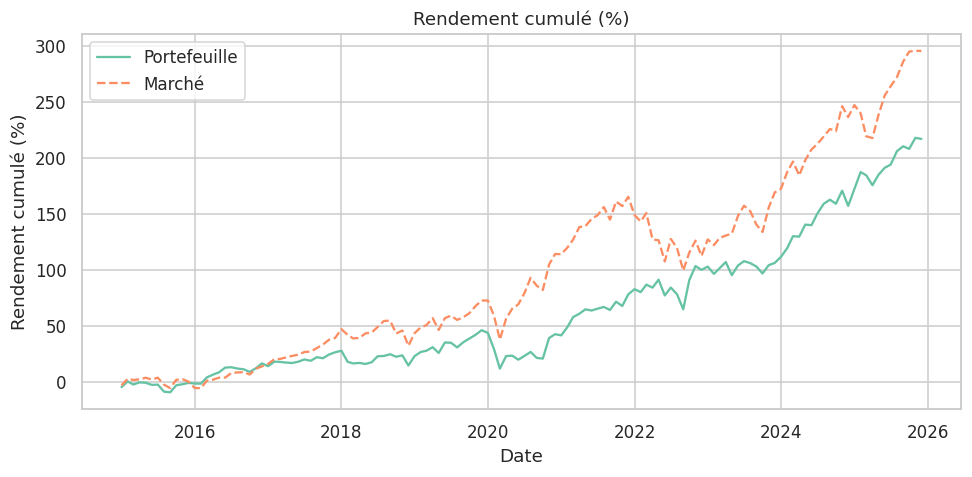

In [29]:
# Rendements cumulés : portefeuille et marché
cumul_p = (1 + data["Portefeuille"] / 100).cumprod() - 1
cumul_m = (1 + (data["Mkt-RF"] + data["RF"]) / 100).cumprod() - 1

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(dates, cumul_p * 100, label="Portefeuille")
ax.plot(dates, cumul_m * 100, label="Marché", linestyle="--")
ax.set_title("Rendement cumulé (%)")
ax.set_xlabel("Date")
ax.set_ylabel("Rendement cumulé (%)")
ax.legend()
plt.tight_layout()
plt.show()

### 5.2 Distribution des rendements en excès

L'histogramme montre la forme de la distribution (symétrie, queues épaisses), ce qui conditionne la validité des tests.

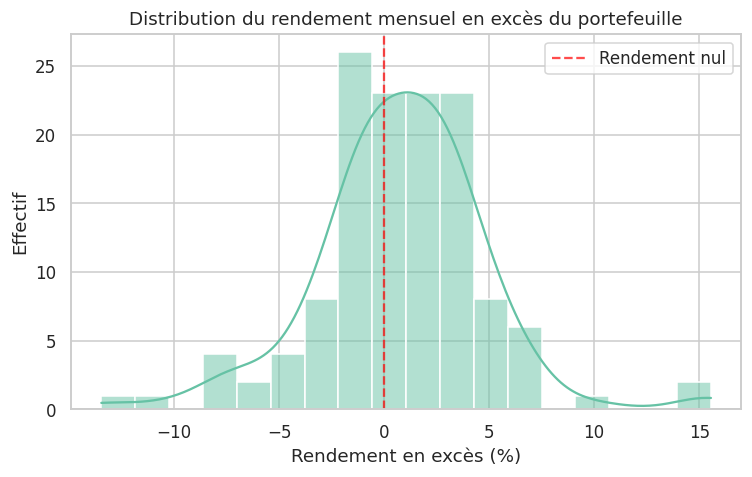

In [30]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.histplot(data["Rp_exc"], kde=True, alpha=0.5, ax=ax)
ax.axvline(0, color="red", linestyle="--", alpha=0.7, label="Rendement nul")
ax.set_title("Distribution du rendement mensuel en excès du portefeuille")
ax.set_xlabel("Rendement en excès (%)")
ax.set_ylabel("Effectif")
ax.legend()
plt.tight_layout()
plt.show()

### 5.3 Relation entre le portefeuille et le marché

Un nuage de points avec une droite de régression visualise le modèle à un facteur : **la pente est le bêta de marché**, l'ordonnée à l'origine est l'alpha.

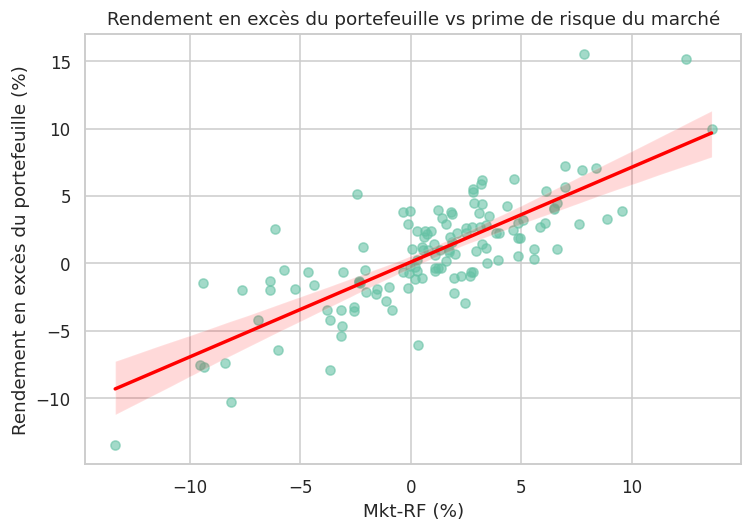

In [31]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.regplot(data=data, x="Mkt-RF", y="Rp_exc", scatter_kws={"alpha": 0.6}, line_kws={"color": "red"}, ax=ax)
ax.set_title("Rendement en excès du portefeuille vs prime de risque du marché")
ax.set_xlabel("Mkt-RF (%)")
ax.set_ylabel("Rendement en excès du portefeuille (%)")
plt.tight_layout()
plt.show()

### 5.4 Boîtes à moustaches et corrélations

Les boîtes à moustaches comparent l'échelle des variables. La matrice de corrélation indique si les facteurs sont liés entre eux : **deux facteurs très corrélés (multicolinéarité) rendent les bêtas imprécis**.

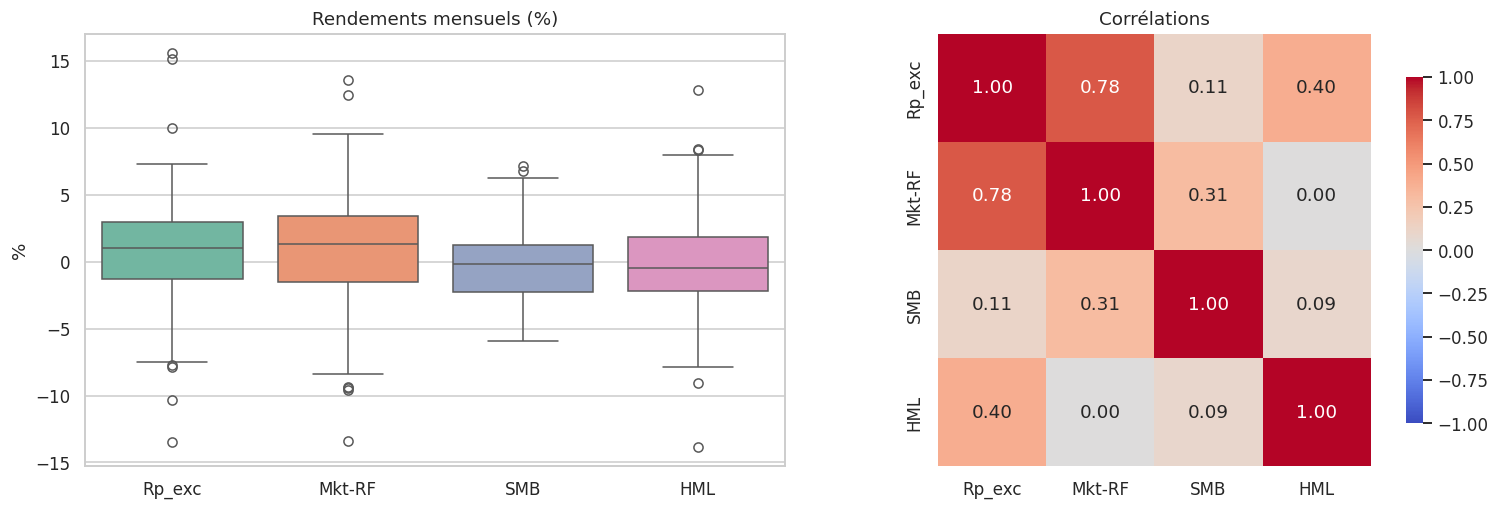

In [32]:
variables_reg = ["Rp_exc", "Mkt-RF", "SMB", "HML"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1]})
sns.boxplot(data=data[variables_reg], ax=axes[0])
axes[0].set_title("Rendements mensuels (%)")
axes[0].set_ylabel("%")

sns.heatmap(data[variables_reg].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.8}, ax=axes[1])
axes[1].set_title("Corrélations")
plt.tight_layout()
plt.show()

## 6. Estimation et comparaison des modèles

### 6.1 Principe de la comparaison

On compare trois modèles, du plus simple au plus riche. La **référence** (*baseline*) est un modèle sans facteur qui prédit toujours la moyenne du rendement en excès : l'alpha est alors simplement la moyenne.

| Modèle | Équation |
|---|---|
| **Référence** (sans facteur) | $R_p - R_f = \alpha + \varepsilon$ |
| **CAPM** (un facteur) | $R_p - R_f = \alpha + \beta\,(R_m - R_f) + \varepsilon$ |
| **Fama-French** (trois facteurs) | $R_p - R_f = \alpha + \beta_1 (R_m - R_f) + \beta_2 SMB + \beta_3 HML + \varepsilon$ |

Tout modèle utile doit faire mieux que la référence, et le modèle à trois facteurs doit apporter **plus que le CAPM**. Comme on ajoute des variables, on compare avec le **R² ajusté**, qui pénalise la complexité (le R² simple augmente toujours).

In [33]:
y = data["Rp_exc"]
X0 = pd.DataFrame({"const": 1.0}, index=data.index)
X1 = sm.add_constant(data[["Mkt-RF"]])
X3 = sm.add_constant(data[["Mkt-RF", "SMB", "HML"]])

m_ref = sm.OLS(y, X0).fit()
m_capm = sm.OLS(y, X1).fit()
m_ff3 = sm.OLS(y, X3).fit()

print(m_ff3.summary())

                            OLS Regression Results                            
Dep. Variable:                 Rp_exc   R-squared:                       0.793
Model:                            OLS   Adj. R-squared:                  0.788
Method:                 Least Squares   F-statistic:                     163.5
Date:                Sat, 07 Nov 2026   Prob (F-statistic):           1.34e-43
Time:                        23:00:30   Log-Likelihood:                -267.35
No. Observations:                 132   AIC:                             542.7
Df Residuals:                     128   BIC:                             554.2
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0573      0.168      0.342      0.7

### 6.2 Tableau comparatif

In [34]:
def ligne(modele, nom):
    ci = modele.conf_int().loc["const"]
    out = {
        "Modèle": nom,
        "Alpha (% / mois)": modele.params["const"],
        "IC 95 % alpha (bas)": ci[0],
        "IC 95 % alpha (haut)": ci[1],
        "p-value alpha": modele.pvalues["const"],
    }
    for f in ["Mkt-RF", "SMB", "HML"]:
        out[f"Bêta {f}"] = modele.params.get(f, np.nan)
        out[f"p-value {f}"] = modele.pvalues.get(f, np.nan)
    out["R²"] = modele.rsquared
    out["R² ajusté"] = modele.rsquared_adj
    out["AIC"] = modele.aic
    out["N"] = int(modele.nobs)
    return out

tableau = (pd.DataFrame([ligne(m_ref, "Référence (sans facteur)"),
                         ligne(m_capm, "CAPM (1 facteur)"),
                         ligne(m_ff3, "Fama-French (3 facteurs)")])
           .set_index("Modèle").T)
tableau.round(4)

Modèle,Référence (sans facteur),CAPM (1 facteur),Fama-French (3 facteurs)
Alpha (% / mois),0.8003,0.1037,0.0573
IC 95 % alpha (bas),0.1035,-0.3442,-0.2744
IC 95 % alpha (haut),1.4970,0.5517,0.3890
p-value alpha,0.0247,0.6476,0.7329
Bêta Mkt-RF,NaN,0.7044,0.7530
p-value Mkt-RF,NaN,0.0000,0.0000
Bêta SMB,NaN,NaN,-0.2654
p-value SMB,NaN,NaN,0.0000
Bêta HML,NaN,NaN,0.4456
p-value HML,NaN,NaN,0.0000


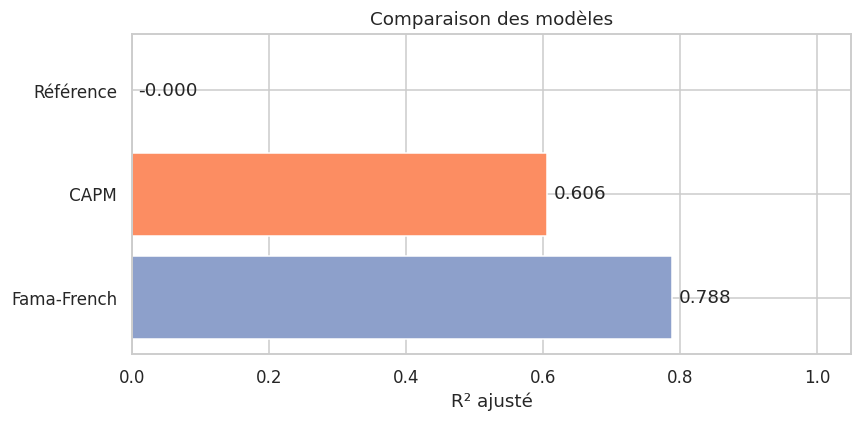

In [35]:
# Graphique : R² ajusté des trois modèles
fig, ax = plt.subplots(figsize=(8, 4))
valeurs = [m_ref.rsquared_adj, m_capm.rsquared_adj, m_ff3.rsquared_adj]
noms_m = ["Référence", "CAPM", "Fama-French"]
ax.barh(noms_m, valeurs, color=sns.color_palette("Set2", 3))
ax.invert_yaxis()
for i, v in enumerate(valeurs):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center")
ax.set_xlim(0, 1.05)
ax.set_xlabel("R² ajusté")
ax.set_title("Comparaison des modèles")
plt.tight_layout()
plt.show()

### 6.3 Le modèle à trois facteurs apporte-t-il vraiment plus ?

Le **test F de modèles emboîtés** teste $H_0 : \beta_{SMB} = \beta_{HML} = 0$. Si la p-value est inférieure à 0,05, ajouter la taille et la valeur améliore significativement le modèle.

In [36]:
f_stat, p_f, ddl = m_ff3.compare_f_test(m_capm)
print(f"Test F (SMB et HML ajoutés au CAPM) : F = {f_stat:.2f}, p-value = {p_f:.4f}")
print(f"R² ajusté : CAPM = {m_capm.rsquared_adj:.3f} | Fama-French = {m_ff3.rsquared_adj:.3f}")
print(f"AIC       : CAPM = {m_capm.aic:.1f} | Fama-French = {m_ff3.aic:.1f}  (plus bas = meilleur)")

Test F (SMB et HML ajoutés au CAPM) : F = 56.91, p-value = 0.0000
R² ajusté : CAPM = 0.606 | Fama-French = 0.788
AIC       : CAPM = 622.7 | Fama-French = 542.7  (plus bas = meilleur)


### 6.4 Robustesse des tests

Les p-values du tableau supposent des erreurs de variance constante et sans autocorrélation. On les compare à des erreurs **robustes** (Newey-West, `HAC`). Si les conclusions ne changent pas, elles sont plus fiables.

In [37]:
m_ff3_hac = sm.OLS(y, X3).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
comparaison = pd.DataFrame({
    "Coefficient": m_ff3.params,
    "p-value (MCO)": m_ff3.pvalues,
    "p-value (robuste HAC)": m_ff3_hac.pvalues,
})
comparaison.round(4)

,Coefficient,p-value (MCO),p-value (robuste HAC)
const,0.0573,0.7329,0.7268
Mkt-RF,0.7530,0.0000,0.0000
SMB,-0.2654,0.0000,0.0001
HML,0.4456,0.0000,0.0000


### 6.5 Évaluation hors échantillon

Un bon ajustement sur l'échantillon peut cacher du surapprentissage. Comme dans le TP des manchots, on garde un **jeu de test** à l'écart : ici, les derniers mois (découpage **chronologique**, jamais aléatoire pour des séries temporelles). On compare l'erreur de chaque modèle à celle de la référence.

In [38]:
n_train = int(0.75 * len(data))
idx_train, idx_test = data.index[:n_train], data.index[n_train:]
print("Entraînement :", len(idx_train), "mois | Test :", len(idx_test), "mois")

resultats = []
for nom, X_full in [("Référence", X0), ("CAPM", X1), ("Fama-French", X3)]:
    modele = sm.OLS(y.loc[idx_train], X_full.loc[idx_train]).fit()
    pred = modele.predict(X_full.loc[idx_test])
    erreur = y.loc[idx_test] - pred
    resultats.append({"Modèle": nom, "RMSE test (%)": float(np.sqrt((erreur ** 2).mean())),
                      "SSE": float((erreur ** 2).sum())})

tab_test = pd.DataFrame(resultats).set_index("Modèle")
sse_ref = tab_test.loc["Référence", "SSE"]
tab_test["R² hors échantillon"] = 1 - tab_test["SSE"] / sse_ref
tab_test.drop(columns="SSE").round(3)

Entraînement : 99 mois | Test : 33 mois


,RMSE test (%),R² hors échantillon
Modèle,,
Référence,2.988,0.000
CAPM,2.631,0.225
Fama-French,1.920,0.587


## 7. Diagnostic du modèle à trois facteurs

### 7.1 Analyse des résidus

Les tests de significativité supposent que les résidus ne présentent ni structure, ni autocorrélation, ni forte non-normalité. On le vérifie graphiquement et par des tests.

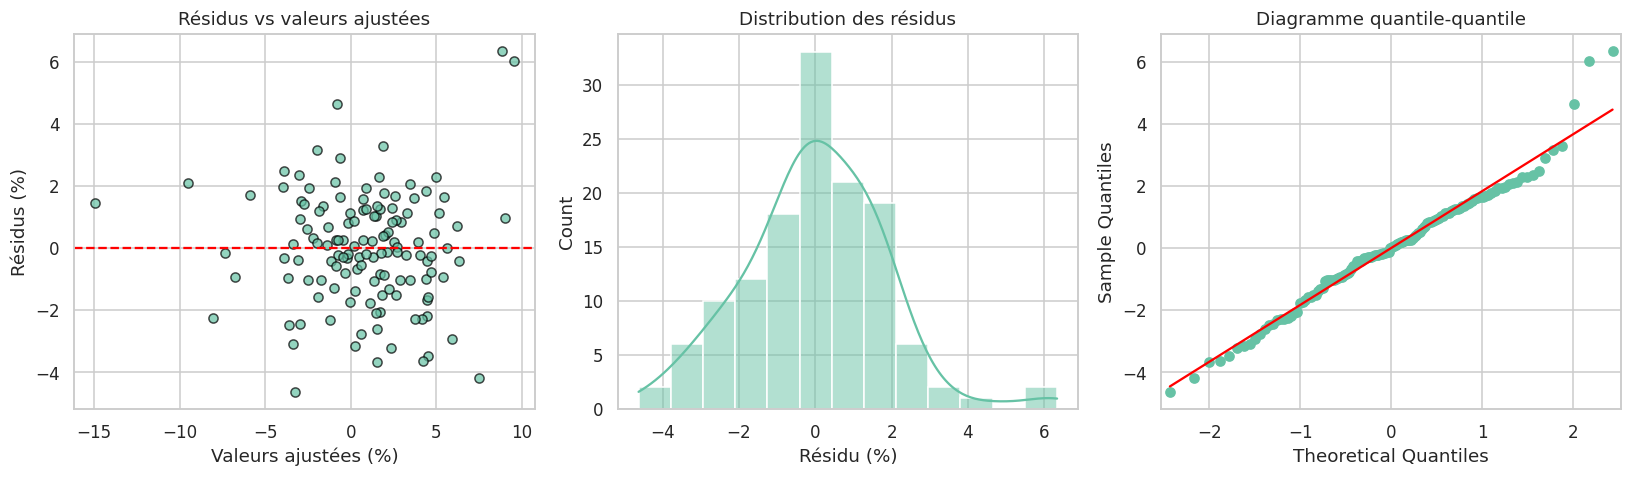

Durbin-Watson (autocorrélation, proche de 2 = absente) : 1.74
Jarque-Bera (normalité)            : p = 0.019
Breusch-Pagan (variance constante) : p = 0.089


In [39]:
residus = m_ff3.resid
ajustees = m_ff3.fittedvalues

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].scatter(ajustees, residus, alpha=0.7, edgecolor="k")
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Résidus vs valeurs ajustées")
axes[0].set_xlabel("Valeurs ajustées (%)")
axes[0].set_ylabel("Résidus (%)")

sns.histplot(residus, kde=True, alpha=0.5, ax=axes[1])
axes[1].set_title("Distribution des résidus")
axes[1].set_xlabel("Résidu (%)")

sm.qqplot(residus, line="s", ax=axes[2])
axes[2].set_title("Diagramme quantile-quantile")
plt.tight_layout()
plt.show()

jb_stat, jb_p, skew, kurt = jarque_bera(residus)
bp_stat, bp_p, _, _ = het_breuschpagan(residus, X3)
print(f"Durbin-Watson (autocorrélation, proche de 2 = absente) : {durbin_watson(residus):.2f}")
print(f"Jarque-Bera (normalité)            : p = {jb_p:.3f}")
print(f"Breusch-Pagan (variance constante) : p = {bp_p:.3f}")

### 7.2 Stabilité des coefficients dans le temps

C'est l'équivalent de la courbe d'apprentissage : on estime le modèle sur une **fenêtre glissante de 36 mois**. Si l'alpha et les bêtas bougent beaucoup, l'hypothèse de coefficients constants est fragile.

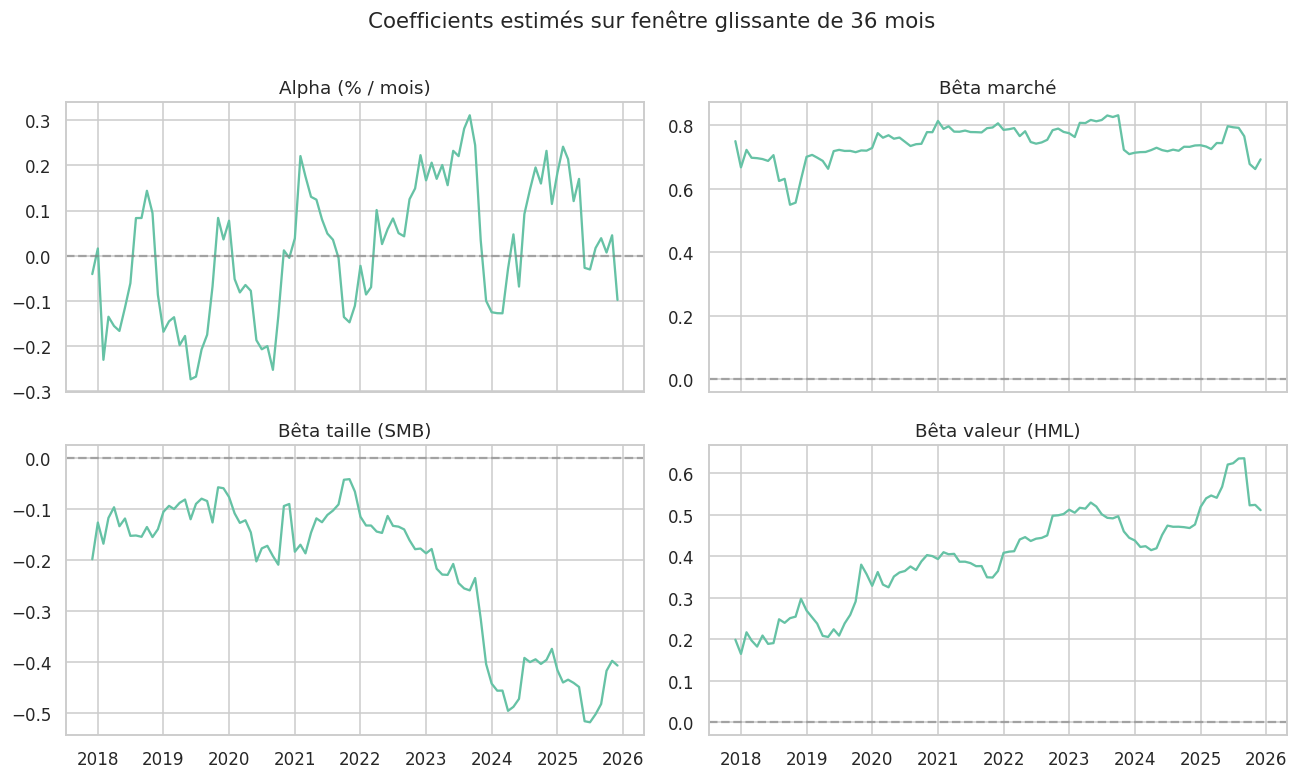

In [40]:
fenetre = 36
roll = RollingOLS(y, X3, window=fenetre).fit()
params_roll = roll.params.copy()
params_roll.index = dates

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, col, titre in zip(axes.ravel(), ["const", "Mkt-RF", "SMB", "HML"],
                          ["Alpha (% / mois)", "Bêta marché", "Bêta taille (SMB)", "Bêta valeur (HML)"]):
    ax.plot(params_roll.index, params_roll[col])
    ax.axhline(0, color="grey", linestyle="--", alpha=0.6)
    ax.set_title(titre)
plt.suptitle(f"Coefficients estimés sur fenêtre glissante de {fenetre} mois", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 8. Interprétation du modèle

### 8.1 Coefficients et intervalles de confiance

Le graphique montre chaque coefficient avec son intervalle de confiance à 95 %. **Un intervalle qui contient 0 signifie que le coefficient n'est pas significativement différent de 0.**

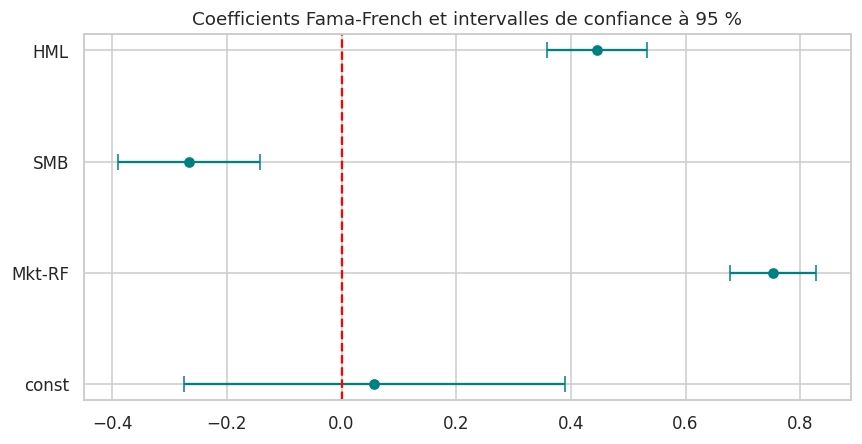

In [41]:
ci = m_ff3.conf_int()
coef = m_ff3.params
noms = list(coef.index)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.errorbar(coef.values, range(len(noms)),
            xerr=[coef.values - ci[0].values, ci[1].values - coef.values],
            fmt="o", capsize=5, color="teal")
ax.axvline(0, color="red", linestyle="--")
ax.set_yticks(range(len(noms)))
ax.set_yticklabels(noms)
ax.set_title("Coefficients Fama-French et intervalles de confiance à 95 %")
plt.tight_layout()
plt.show()

In [42]:
def signif(p): return "significatif" if p < 0.05 else "non significatif"

a, p_a = m_ff3.params["const"], m_ff3.pvalues["const"]
lo, hi = m_ff3.conf_int().loc["const"]
a_annuel = ((1 + a / 100) ** 12 - 1) * 100

print(f"1) Marché : bêta = {m_ff3.params['Mkt-RF']:.2f} ({signif(m_ff3.pvalues['Mkt-RF'])}). "
      f"Le portefeuille est {'plus' if m_ff3.params['Mkt-RF'] > 1 else 'moins'} sensible que le marché.")
print(f"2) Taille : bêta SMB = {m_ff3.params['SMB']:.2f} ({signif(m_ff3.pvalues['SMB'])}). "
      f"{'Biais vers les petites capitalisations.' if m_ff3.params['SMB'] > 0 else 'Biais vers les grandes capitalisations.'}")
print(f"3) Valeur : bêta HML = {m_ff3.params['HML']:.2f} ({signif(m_ff3.pvalues['HML'])}). "
      f"{'Biais Value.' if m_ff3.params['HML'] > 0 else 'Biais Croissance (Growth).'}")
print(f"4) Alpha = {a:.3f} %/mois (≈ {a_annuel:.1f} %/an), IC 95 % [{lo:.3f} ; {hi:.3f}], "
      f"p = {p_a:.3f} → {signif(p_a)}.")
print(f"5) R² ajusté : CAPM {m_capm.rsquared_adj:.2f} → Fama-French {m_ff3.rsquared_adj:.2f} ; "
      f"test F des facteurs ajoutés : p = {p_f:.3f} ({signif(p_f)}).")

1) Marché : bêta = 0.75 (significatif). Le portefeuille est moins sensible que le marché.
2) Taille : bêta SMB = -0.27 (significatif). Biais vers les grandes capitalisations.
3) Valeur : bêta HML = 0.45 (significatif). Biais Value.
4) Alpha = 0.057 %/mois (≈ 0.7 %/an), IC 95 % [-0.274 ; 0.389], p = 0.733 → non significatif.
5) R² ajusté : CAPM 0.61 → Fama-French 0.79 ; test F des facteurs ajoutés : p = 0.000 (significatif).


### 8.2 L'alpha peut-il venir du hasard ?

Pour mesurer l'incertitude de l'alpha sans hypothèse sur la forme des erreurs, on utilise le **bootstrap** : on retire au hasard (avec remise) des mois de l'échantillon, on réestime le modèle, et on répète l'opération 2000 fois. La dispersion des alphas obtenus montre à quel point l'estimation est instable.

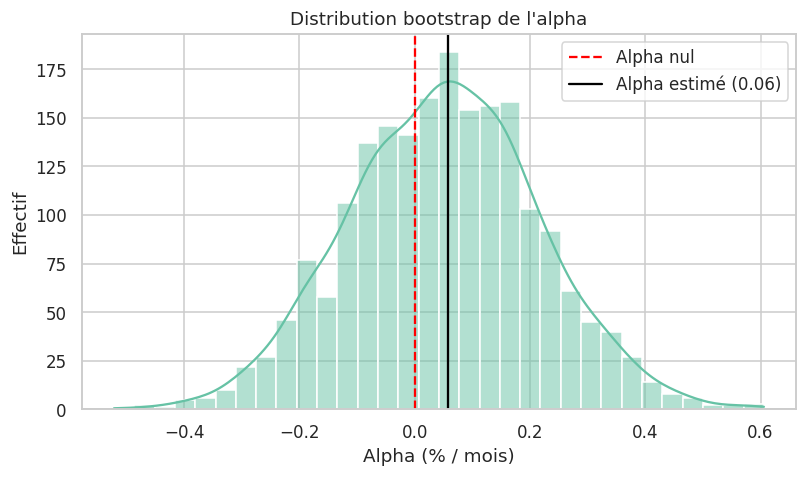

IC 95 % bootstrap de l'alpha : [-0.269 ; 0.371]  |  IC théorique : [-0.274 ; 0.389]


In [43]:
rng = np.random.default_rng(42)
alphas_boot = []
for _ in range(2000):
    idx = rng.integers(0, len(data), len(data))
    m_b = sm.OLS(y.iloc[idx].values, X3.iloc[idx].values).fit()
    alphas_boot.append(m_b.params[0])
alphas_boot = np.array(alphas_boot)
b_lo, b_hi = np.percentile(alphas_boot, [2.5, 97.5])

fig, ax = plt.subplots(figsize=(7.5, 4.5))
sns.histplot(alphas_boot, kde=True, alpha=0.5, ax=ax)
ax.axvline(0, color="red", linestyle="--", label="Alpha nul")
ax.axvline(a, color="black", label=f"Alpha estimé ({a:.2f})")
ax.set_xlabel("Alpha (% / mois)")
ax.set_ylabel("Effectif")
ax.set_title("Distribution bootstrap de l'alpha")
ax.legend()
plt.tight_layout()
plt.show()
print(f"IC 95 % bootstrap de l'alpha : [{b_lo:.3f} ; {b_hi:.3f}]  |  IC théorique : [{lo:.3f} ; {hi:.3f}]")

## 9. Utiliser le modèle sur une nouvelle observation

Une fois estimé, le modèle donne le rendement en excès **attendu** pour des valeurs données des facteurs, avec un **intervalle de prédiction** qui reflète le risque propre du portefeuille.

In [44]:
nouveau_mois = pd.DataFrame([{"Mkt-RF": 2.0, "SMB": 0.5, "HML": -1.0}])   # mois fictif
X_new = sm.add_constant(nouveau_mois, has_constant="add")[X3.columns]

pred = m_ff3.get_prediction(X_new).summary_frame(alpha=0.05)
print("Facteurs : Mkt-RF=2.0 %, SMB=0.5 %, HML=-1.0 %")
print(f"Rendement en excès attendu : {pred['mean'].iloc[0]:.2f} %")
print(f"Intervalle de prédiction à 95 % : [{pred['obs_ci_lower'].iloc[0]:.2f} ; {pred['obs_ci_upper'].iloc[0]:.2f}] %")

Facteurs : Mkt-RF=2.0 %, SMB=0.5 %, HML=-1.0 %
Rendement en excès attendu : 0.98 %
Intervalle de prédiction à 95 % : [-2.72 ; 4.69] %
